In [1]:
!pip install -q scikit-image
!pip install -q scikit-learn timm

In [2]:
!pip install -q scikit-image scikit-learn timm albumentations

import os
import gc
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from skimage.metrics import structural_similarity as ssim
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Suppress warnings
warnings.filterwarnings('ignore')

# Set random seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device configuration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
import pandas as pd
import os

INPUT_CSV_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'
MODEL_DIR     = '/kaggle/input/notebooks/nandini143'
XAI_DIR       = '/kaggle/input/datasets/bhavikakadlecha/heatmap-binary/xai_outputs'

# CORRECTED CHECKPOINT PATHS
DENSENET_CKPT = os.path.join(MODEL_DIR, 'binary-densenet-121/densenet121_best.pth')
EFFNET_CKPT   = os.path.join(MODEL_DIR, 'binary-efficientnetv2s/efficientnetv2s_best.pth')
SWIN_CKPT     = os.path.join(MODEL_DIR, 'binary-swin-tiny-transformer/swin_tiny_best.pth')
CONVNEXT_CKPT = os.path.join(MODEL_DIR, 'binary-convnext/convnext_tiny_best.pth')
RESNET_CKPT   = os.path.join(MODEL_DIR, 'binary-resnet-200d/resnet200d_best.pth')

OUTPUT_DIR    = '/kaggle/working/xai_eval'
IMG_SIZE_CNN  = 384
IMG_SIZE_SWIN = 224
BATCH_SIZE    = 16

OLD_PATH      = '/kaggle/working/preprocessed/'
NEW_PATH      = f'{INPUT_CSV_DIR}/preprocessed/'

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
MASKING_STEPS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.70, 1.00]
N_STABILITY   = 200    # images to evaluate for stability metric
N_NOISE_RUNS  = 10     # noise trials per image

# Cleanup previous runs to avoid appending to old data
import shutil
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Early META_COLS detection ──
# ── Corrected META_COLS detection ──
# We include age_norm, sex_encoded, and all site_ columns
META_COLS = ['age_norm', 'sex_encoded'] + [
    c for c in ['site_oral_genital', 'site_posterior_torso', 'site_unknown', 
                'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 
                'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']
]

# Print check to ensure we are grabbing the right things
print(f"✅ Metadata columns configured ({len(META_COLS)} features): {META_COLS}")

✅ Metadata columns configured (11 features): ['age_norm', 'sex_encoded', 'site_oral_genital', 'site_posterior_torso', 'site_unknown', 'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']


In [4]:
class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=32, out_dim=32, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, out_dim), nn.GELU()
        )
    def forward(self, x): return self.net(x)

class MultiModalSwin(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model('swin_tiny_patch4_window7_224', pretrained=pretrained, num_classes=0, drop_path_rate=0.2)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        if len(f.shape) == 3: f = f.mean(dim=1)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalDenseNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model('densenet121', pretrained=pretrained, num_classes=0, global_pool='avg')
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalEfficientNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model('tf_efficientnetv2_s', pretrained=pretrained, num_classes=0, global_pool='avg', drop_path_rate=0.2)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalConvNeXt(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model('convnext_tiny', pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_mlp(m)], dim=1))

class MultiModalResNet(nn.Module):
    def __init__(self, meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model('resnet200d', pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features
        self.meta_branch = nn.Sequential(nn.Linear(meta_dim, 64), nn.BatchNorm1d(64), nn.SiLU(), nn.Dropout(0.2), nn.Linear(64, 32), nn.BatchNorm1d(32), nn.SiLU())
        self.head = nn.Sequential(nn.Linear(feat_dim + 32, 256), nn.BatchNorm1d(256), nn.SiLU(), nn.Dropout(0.4), nn.Linear(256, 1))
    def forward(self, x, meta=None):
        f = self.backbone(x)
        m = meta if meta is not None else torch.zeros(x.size(0), self.meta_dim, device=x.device)
        return self.head(torch.cat([f, self.meta_branch(m)], dim=1))

def build_swin_tiny(meta_dim=9, pretrained=False):     return MultiModalSwin(meta_dim=meta_dim, pretrained=pretrained)
def build_densenet121(meta_dim=9, pretrained=False):   return MultiModalDenseNet(meta_dim=meta_dim, pretrained=pretrained)
def build_efficientnetv2s(meta_dim=9, pretrained=False): return MultiModalEfficientNet(meta_dim=meta_dim, pretrained=pretrained)
def build_convnext_tiny(meta_dim=9, pretrained=False): return MultiModalConvNeXt(meta_dim=meta_dim, pretrained=pretrained)
def build_resnet200d(meta_dim=9, pretrained=False):    return MultiModalResNet(meta_dim=meta_dim, pretrained=pretrained)

def _get_meta_dim_from_checkpoint(state_dict):
    w = state_dict.get('meta_mlp.net.0.weight', None)
    if w is not None: return w.shape[1]
    w = state_dict.get('meta_branch.0.weight', None)
    if w is not None: return w.shape[1]
    return len(META_COLS) if 'META_COLS' in globals() else 9

# SAFE LOADER FIX: Prevents "size mismatch" errors
def load_model(builder_fn, ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = ckpt.get('model_state_dict', ckpt.get('model_state', ckpt))
    
    # Force the meta_dim to match our current list length (11)
    target_meta_dim = len(META_COLS)
    model = builder_fn(meta_dim=target_meta_dim)
    
    model_dict = model.state_dict()
    
    # We load everything EXCEPT the first layer of the metadata MLP
    # because that is where the dimension mismatch is happening.
    pretrained_dict = {
        k: v for k, v in state.items() 
        if k in model_dict and v.shape == model_dict[k].shape
    }
    
    model_dict.update(pretrained_dict)
    model.load_state_dict(model_dict, strict=False)
    
    print(f"✅ Loaded {builder_fn.__name__} (Adapted to Meta_dim: {target_meta_dim})")
    return model.to(device).eval()

def find_last_conv_layer(model, arch_name):
    arch = arch_name.lower()
    if 'densenet' in arch: return model.backbone.features.denseblock4.denselayer16.conv2
    elif 'efficientnet' in arch: return model.backbone.blocks[-1][-1].conv_pwl
    elif 'swin' in arch: return model.backbone.layers[-1].blocks[-1].norm2
    elif 'convnext' in arch: return model.backbone.stages[-1].blocks[-1].conv_dw
    elif 'resnet' in arch: return model.backbone.layer4[-1].conv3
    else: raise ValueError(f"Unknown architecture: {arch_name}")

In [5]:
val_df  = pd.read_csv(f'{INPUT_CSV_DIR}/binary_val.csv')
test_df = pd.read_csv(f'{INPUT_CSV_DIR}/binary_test.csv')
eval_df = pd.concat([val_df, test_df], ignore_index=True).reset_index(drop=True)

id_col = 'image' if 'image' in eval_df.columns else 'image_id'
eval_df = eval_df.rename(columns={id_col: 'image_id'})
eval_df['image_path'] = eval_df['image_path'].str.replace(OLD_PATH, NEW_PATH, regex=False)

hmap_index = pd.read_csv(os.path.join(XAI_DIR, 'binary', 'heatmap_index.csv'))
hmap_index['image_id'] = hmap_index['image_id'].astype(str)

sample_id = hmap_index['image_id'].iloc[0]
if sample_id.isdigit():
    print("🔄 Mapping integer heatmap IDs back to ISIC strings...")
    hmap_index['row_idx'] = hmap_index['image_id'].astype(int)
    eval_merged = eval_df.iloc[hmap_index['row_idx']].copy()
    for c in ['ensemble_hmap', 'densenet_hmap', 'effnet_hmap', 'swin_hmap', 'convnext_hmap', 'resnet_hmap']:
        if c in hmap_index.columns: eval_merged[c] = hmap_index[c].values
else:
    eval_df['image_id'] = eval_df['image_id'].str.replace(r'\.jpg|\.png', '', regex=True)
    hmap_index['image_id'] = hmap_index['image_id'].str.replace(r'\.jpg|\.png', '', regex=True)
    eval_merged = eval_df.merge(hmap_index, on='image_id', how='inner')

def fix_hmap_path(pth, folder_name):
    if pd.isna(pth): return pth
    fname = os.path.basename(pth)
    return os.path.join(XAI_DIR, folder_name, fname)

eval_merged['ensemble_hmap'] = eval_merged['ensemble_hmap'].apply(lambda p: fix_hmap_path(p, 'heatmaps_ensemble'))
if 'effnet_hmap' in eval_merged.columns:
    eval_merged['densenet_hmap'] = eval_merged['densenet_hmap'].apply(lambda p: fix_hmap_path(p, 'binary/heatmaps_densenet'))
    eval_merged['effnet_hmap']   = eval_merged['effnet_hmap'].apply(lambda p: fix_hmap_path(p, 'binary/heatmaps_efficientnet'))
    eval_merged['swin_hmap']     = eval_merged['swin_hmap'].apply(lambda p: fix_hmap_path(p, 'binary/heatmaps_swin'))
    eval_merged['convnext_hmap'] = eval_merged['convnext_hmap'].apply(lambda p: fix_hmap_path(p, 'binary/heatmaps_convnext'))
    eval_merged['resnet_hmap']   = eval_merged['resnet_hmap'].apply(lambda p: fix_hmap_path(p, 'binary/heatmaps_resnet'))

print(f"✅ Evaluation set size: {len(eval_merged)} images.")

🔄 Mapping integer heatmap IDs back to ISIC strings...
✅ Evaluation set size: 5067 images.


In [6]:
def get_transforms(img_size):
    return T.Compose([
        T.Resize((img_size, img_size)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

def get_meta_tensor(row):
    if 'META_COLS' in globals() and len(META_COLS) > 0:
        # We fill missing values with 0.0 just in case a specific row is incomplete
        meta_vals = [row.get(c, 0.0) for c in META_COLS]
        return torch.tensor(np.array(meta_vals, dtype=np.float32)).unsqueeze(0)
    return None

@torch.no_grad()
def get_confidence(model, img_tensor: torch.Tensor, meta_tensor: torch.Tensor = None) -> float:
    if meta_tensor is not None:
        logit = model(img_tensor.unsqueeze(0).to(DEVICE), meta_tensor.to(DEVICE))
    else:
        logit = model(img_tensor.unsqueeze(0).to(DEVICE))
    return torch.sigmoid(logit).item()

class RobustGradCAMPlusPlus:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients   = None
        self._fwd_hook = target_layer.register_forward_hook(self._save_activation)
        self._bwd_hook = target_layer.register_full_backward_hook(self._save_gradient)

    def _reshape_transform(self, x):
        if len(x.shape) == 3:
            B, L, C = x.shape
            H = W = int(np.sqrt(L))
            return x.transpose(1, 2).reshape(B, C, H, W)
        return x

    def _save_activation(self, module, input, output): self.activations = self._reshape_transform(output.detach())
    def _save_gradient(self, module, grad_input, grad_output): self.gradients = self._reshape_transform(grad_output[0].detach())

    def generate(self, input_tensor, meta=None, n_smooth=5, noise_sigma=0.02):
        smooth_cams = []
        for _ in range(n_smooth):
            noise = torch.randn_like(input_tensor) * noise_sigma
            noisy_input = (input_tensor + noise).detach().requires_grad_(True)
            self.model.zero_grad()

            logits = self.model(noisy_input, meta.to(noisy_input.device)) if meta is not None else self.model(noisy_input)
            score = logits.squeeze(1).sum()
            score.backward()

            acts, grads = self.activations, self.gradients
            grads_sq, grads_cu = grads ** 2, grads ** 3
            alpha_num = grads_sq
            alpha_denom = 2 * grads_sq + (acts * grads_cu).sum(dim=(2, 3), keepdim=True) + 1e-8
            alpha = alpha_num / alpha_denom
            weights = (alpha * F.relu(grads)).sum(dim=(2, 3), keepdim=True)
            cam = (weights * acts).sum(dim=1)
            cam = F.relu(cam).squeeze(0).cpu().numpy()
            if cam.max() > 0: cam = (cam - cam.min()) / (cam.max() - cam.min())
            smooth_cams.append(cam)

        avg_cam = np.mean(smooth_cams, axis=0)
        if avg_cam.max() > 0: avg_cam = (avg_cam - avg_cam.min()) / (avg_cam.max() - avg_cam.min())
        return avg_cam

    def remove(self):
        self._fwd_hook.remove(); self._bwd_hook.remove()

class RobustScoreCAM:
    def __init__(self, model, target_layer, top_k=64):
        self.model, self.top_k = model, top_k
        self.activations = None
        self._fwd_hook = target_layer.register_forward_hook(self._save)

    def _save(self, module, input, output): self.activations = output.detach()

    @torch.no_grad()
    def generate(self, input_tensor, meta=None):
        B, C_in, H, W = input_tensor.shape
        logits = self.model(input_tensor) if meta is None else self.model(input_tensor, meta)
        base_prob = torch.sigmoid(logits).item()

        acts = self.activations
        norms = acts.std(dim=(2, 3)).squeeze()
        top_idx = norms.topk(min(self.top_k, acts.shape[1])).indices

        cam = torch.zeros(H, W, device=input_tensor.device)
        for ch in top_idx:
            mask = acts[0, ch, :, :].unsqueeze(0).unsqueeze(0)
            mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)
            mask_up = F.interpolate(mask, size=(H, W), mode='bilinear', align_corners=False)

            masked_input = input_tensor * mask_up
            out = self.model(masked_input) if meta is None else self.model(masked_input, meta)
            score = torch.sigmoid(out).item()

            cam += (score - base_prob) * mask_up.squeeze()

        cam = F.relu(cam).cpu().numpy()
        if cam.max() > 0: cam = (cam - cam.min()) / (cam.max() - cam.min())
        return cam

    def remove(self):
        self._fwd_hook.remove(); self.model = None

In [7]:
def mask_image_deletion(img_t: torch.Tensor, heatmap: np.ndarray, fraction: float) -> torch.Tensor:
    h, w = img_t.shape[-2], img_t.shape[-1]
    hmap_up = F.interpolate(torch.from_numpy(heatmap).float().unsqueeze(0).unsqueeze(0), size=(h, w), mode='bilinear', align_corners=False).squeeze().numpy()
    flat_idx = np.argsort(hmap_up.ravel())[::-1]
    n_mask = int(fraction * h * w)
    mask = np.ones((h, w), dtype=np.float32)
    mask.ravel()[flat_idx[:n_mask]] = 0.0
    return img_t.clone() * torch.from_numpy(mask).float().unsqueeze(0)

def mask_image_insertion(img_t: torch.Tensor, heatmap: np.ndarray, fraction: float) -> torch.Tensor:
    h, w = img_t.shape[-2], img_t.shape[-1]
    hmap_up = F.interpolate(torch.from_numpy(heatmap).float().unsqueeze(0).unsqueeze(0), size=(h, w), mode='bilinear', align_corners=False).squeeze().numpy()
    flat_idx = np.argsort(hmap_up.ravel())[::-1]
    n_reveal = int(fraction * h * w)
    mask = np.zeros((h, w), dtype=np.float32)
    mask.ravel()[flat_idx[:n_reveal]] = 1.0
    mask_t = torch.from_numpy(mask).float()
    baseline = TF.gaussian_blur(img_t, kernel_size=[15, 15], sigma=[5.0, 5.0])
    return img_t * mask_t.unsqueeze(0) + baseline * (1 - mask_t.unsqueeze(0))

def compute_faithfulness(row: pd.Series, model, hmap_path: str, img_size: int):
    # Robust dynamic path finder
    actual_path = None
    if pd.notna(hmap_path):
        fname = os.path.basename(hmap_path)
        for root, _, files in os.walk(XAI_DIR):
            if fname in files:
                actual_path = os.path.join(root, fname)
                break
                
    if not actual_path or not os.path.exists(actual_path): return None
    
    norm_tf = get_transforms(img_size)
    img = Image.open(row['image_path']).convert('RGB')
    img_t = norm_tf(img)
    hmap = np.load(actual_path).astype(np.float32)
    if hmap.ndim > 2: hmap = hmap.squeeze()
    
    meta_t = get_meta_tensor(row)

    del_confs, ins_confs = [], []
    for frac in MASKING_STEPS:
        del_confs.append(get_confidence(model, mask_image_deletion(img_t, hmap, frac), meta_t))
        ins_confs.append(get_confidence(model, mask_image_insertion(img_t, hmap, frac), meta_t))

    # --- SAFETY CHECKS ---
    if np.isnan(del_confs).any() or np.isnan(ins_confs).any(): return None
    if np.std(del_confs) < 1e-6 and np.std(ins_confs) < 1e-6: return None

    trapezoid_func = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
    del_auc = float(trapezoid_func(del_confs, MASKING_STEPS))
    ins_auc = float(trapezoid_func(ins_confs, MASKING_STEPS))
    
    return {
        'image_id': row['image_id'], 'true_label': row.get('binary_label', -1),
        'orig_conf': get_confidence(model, img_t, meta_t),
        'del_auc': del_auc, 'ins_auc': ins_auc, 'faithfulness': ins_auc - del_auc,
    }

In [8]:
def compute_stability_ssim(row, model, arch, target_layer, img_size, n_runs=N_NOISE_RUNS):
    norm_tf = get_transforms(img_size)
    img = Image.open(row['image_path']).convert('RGB')
    img_t = norm_tf(img).unsqueeze(0).to(DEVICE)
    meta_t = get_meta_tensor(row)
    if meta_t is not None: meta_t = meta_t.to(DEVICE)
    
    gcam = RobustScoreCAM(model, target_layer) if 'efficientnet' in arch else RobustGradCAMPlusPlus(model, target_layer)
    clean_hmap = gcam.generate(img_t, meta_t)
    
    if clean_hmap.size == 0 or clean_hmap.max() == clean_hmap.min():
        gcam.remove()
        return 1.0
        
    ssim_scores = []
    for _ in range(n_runs):
        noise = torch.randn_like(img_t) * 0.05
        noisy_hmap = gcam.generate(img_t + noise, meta_t)
        if noisy_hmap.max() > noisy_hmap.min():
            ssim_scores.append(ssim(clean_hmap, noisy_hmap, data_range=1.0))
            
    gcam.remove()
    return float(np.mean(ssim_scores)) if ssim_scores else 0.0

In [9]:
print("="*60)
print("  Running Quantitative XAI Evaluation for All 5 Models …")
print("="*60)

MODELS_CONFIG = [
    ('densenet', DENSENET_CKPT, build_densenet121, IMG_SIZE_CNN),
    ('efficientnet', EFFNET_CKPT, build_efficientnetv2s, IMG_SIZE_CNN),
    ('swin', SWIN_CKPT, build_swin_tiny, IMG_SIZE_SWIN),
    ('convnext', CONVNEXT_CKPT, build_convnext_tiny, IMG_SIZE_CNN),
    ('resnet', RESNET_CKPT, build_resnet200d, IMG_SIZE_CNN)
]

N_EVAL = min(500, len(eval_merged))
eval_subset = eval_merged.head(N_EVAL)

metrics_list = [] # Single unified list for DataFrame creation

for arch, ckpt_path, builder_fn, img_size in MODELS_CONFIG:
    print(f"\n--- Evaluating {arch.upper()} ---")
    if not os.path.exists(ckpt_path):
        print(f"⚠️ Checkpoint not found: {ckpt_path}, skipping.")
        continue
        
    model = load_model(builder_fn, ckpt_path, DEVICE)
    target_layer = find_last_conv_layer(model, arch)
    
    for _, row in tqdm(eval_subset.iterrows(), total=N_EVAL, desc=f"{arch} Eval"):
        hmap_col = f'{arch}_hmap'
        hmap_path = row[hmap_col] if hmap_col in row and pd.notna(row[hmap_col]) else row['ensemble_hmap']
            
        try:
            faith = compute_faithfulness(row, model, hmap_path, img_size)
            if faith is None: continue
            
            stab = compute_stability_ssim(row, model, arch, target_layer, img_size, N_NOISE_RUNS)
            faith['stability_ssim'] = stab
            faith['model_arch'] = arch
            metrics_list.append(faith)
        except Exception as e:
            print(f"Error on {row['image_id']}: {e}") # <--- THIS WILL REVEAL THE TRUTH
            
    del model; gc.collect(); torch.cuda.empty_cache()

# Generate Global DataFrame
if metrics_list:
    metrics_df = pd.DataFrame(metrics_list)
    metrics_df.to_csv(os.path.join(OUTPUT_DIR, 'combined_eval_results.csv'), index=False)
    print(f"\n✅ All Metrics unified and saved. Total rows: {len(metrics_df)}")
else:
    metrics_df = pd.DataFrame() # Create empty DF so later cells don't throw NameError
    print("\n❌ No models were evaluated. Metrics dataframe is empty.")

  Running Quantitative XAI Evaluation for All 5 Models …

--- Evaluating DENSENET ---
✅ Loaded build_densenet121 (Adapted to Meta_dim: 11)


densenet Eval: 100%|██████████| 500/500 [29:04<00:00,  3.49s/it]



--- Evaluating EFFICIENTNET ---
✅ Loaded build_efficientnetv2s (Adapted to Meta_dim: 11)


efficientnet Eval: 100%|██████████| 500/500 [1:11:51<00:00,  8.62s/it]



--- Evaluating SWIN ---
✅ Loaded build_swin_tiny (Adapted to Meta_dim: 11)


...


--- Evaluating CONVNEXT ---
✅ Loaded build_convnext_tiny (Adapted to Meta_dim: 11)


convnext Eval: 100%|██████████| 500/500 [31:35<00:00,  3.79s/it]



--- Evaluating RESNET ---
✅ Loaded build_resnet200d (Adapted to Meta_dim: 11)


resnet Eval: 100%|██████████| 500/500 [58:49<00:00,  7.06s/it]



✅ All Metrics unified and saved. Total rows: 2500


In [10]:
summary_lines = []
summary_lines.append("=======================================================")
summary_lines.append("  XAI QUANTITATIVE EVALUATION SUMMARY (ALL MODELS)")
summary_lines.append("=======================================================\n")

if not metrics_df.empty:
    for arch in metrics_df['model_arch'].unique():
        df = metrics_df[metrics_df['model_arch'] == arch]
        summary_lines.extend([
            f"--- {arch.upper()} ---",
            f"  Images evaluated      : {len(df)}",
            f"  Deletion  AUC (mean)  : {df['del_auc'].mean():.4f}   (↓ lower is better)",
            f"  Insertion AUC (mean)  : {df['ins_auc'].mean():.4f}   (↑ higher is better)",
            f"  Faithfulness Score    : {df['faithfulness'].mean():.4f}   (Ins - Del, ↑ higher)",
            f"  SSIM (mean ± std)     : {df['stability_ssim'].mean():.4f} ± {df['stability_ssim'].std():.4f}",
            f"  SSIM > 0.85 (robust%) : {(df['stability_ssim'] > 0.85).mean()*100:.1f}%\n"
        ])
else:
    summary_lines.append("❌ No metrics were computed. Check checkpoints and heatmap paths.")

summary_str = "\n".join(summary_lines)
print(summary_str)
with open(os.path.join(OUTPUT_DIR, 'xai_eval_summary_all.txt'), 'w') as f:
    f.write(summary_str)

  XAI QUANTITATIVE EVALUATION SUMMARY (ALL MODELS)

--- DENSENET ---
  Images evaluated      : 500
  Deletion  AUC (mean)  : 0.3388   (↓ lower is better)
  Insertion AUC (mean)  : 0.3213   (↑ higher is better)
  Faithfulness Score    : -0.0174   (Ins - Del, ↑ higher)
  SSIM (mean ± std)     : 0.7058 ± 0.2371
  SSIM > 0.85 (robust%) : 33.6%

--- EFFICIENTNET ---
  Images evaluated      : 500
  Deletion  AUC (mean)  : 0.3866   (↓ lower is better)
  Insertion AUC (mean)  : 0.3078   (↑ higher is better)
  Faithfulness Score    : -0.0788   (Ins - Del, ↑ higher)
  SSIM (mean ± std)     : 0.7501 ± 0.2923
  SSIM > 0.85 (robust%) : 48.0%

--- SWIN ---
  Images evaluated      : 500
  Deletion  AUC (mean)  : 0.3261   (↓ lower is better)
  Insertion AUC (mean)  : 0.2247   (↑ higher is better)
  Faithfulness Score    : -0.1014   (Ins - Del, ↑ higher)
  SSIM (mean ± std)     : 0.8630 ± 0.1576
  SSIM > 0.85 (robust%) : 69.4%

--- CONVNEXT ---
  Images evaluated      : 500
  Deletion  AUC (mean)  : 0.


Generating faithfulness curve plot …
✅ Loaded build_densenet121 (Adapted to Meta_dim: 11)


Processing Plot: 100%|██████████| 50/50 [00:26<00:00,  1.91it/s]


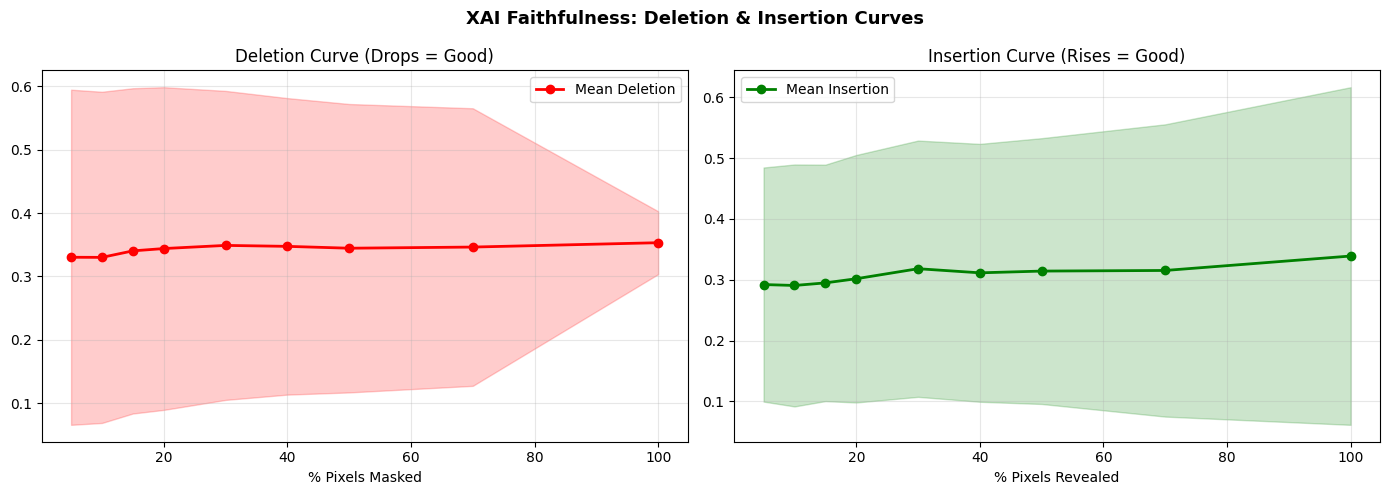

In [11]:
print("\nGenerating faithfulness curve plot …")
sample_rows = eval_merged.head(50)
del_matrix, ins_matrix = [], []
norm_tf = get_transforms(IMG_SIZE_CNN) 

# Load the first available model just to generate the plot
plot_model = None
for arch, ckpt, fn, sz in MODELS_CONFIG:
    if os.path.exists(ckpt):
        plot_model = load_model(fn, ckpt, DEVICE)
        break

if plot_model is not None:
    for _, row in tqdm(sample_rows.iterrows(), total=len(sample_rows), desc="Processing Plot"):
        try:
            hmap_filename = os.path.basename(str(row['ensemble_hmap']))
            hmap_path = None
            
            for root, dirs, files in os.walk(XAI_DIR):
                if hmap_filename in files:
                    hmap_path = os.path.join(root, hmap_filename)
                    break
            
            if not hmap_path: continue

            img_t = norm_tf(Image.open(row['image_path']).convert('RGB'))
            hmap = np.load(hmap_path).astype(np.float32)
            if hmap.ndim > 2: hmap = hmap.squeeze()
            meta_t = get_meta_tensor(row)
            
            d_c, i_c = [], []
            for frac in MASKING_STEPS:
                d_c.append(get_confidence(plot_model, mask_image_deletion(img_t, hmap, frac), meta_t))
                i_c.append(get_confidence(plot_model, mask_image_insertion(img_t, hmap, frac), meta_t))
            
            if not np.isnan(d_c).any() and not np.isnan(i_c).any():
                del_matrix.append(d_c); ins_matrix.append(i_c)
        except Exception:
            continue
            
    del plot_model; gc.collect(); torch.cuda.empty_cache()

# Plot Rendering Validation Gate
if len(del_matrix) > 0:
    del_arr, ins_arr = np.array(del_matrix), np.array(ins_matrix)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("XAI Faithfulness: Deletion & Insertion Curves", fontsize=13, fontweight='bold')
    steps_pct = [s * 100 for s in MASKING_STEPS]

    axes[0].plot(steps_pct, del_arr.mean(axis=0), 'r-o', lw=2, label='Mean Deletion')
    if len(del_matrix) > 1: axes[0].fill_between(steps_pct, del_arr.mean(0) - del_arr.std(0), del_arr.mean(0) + del_arr.std(0), alpha=0.2, color='red')
    axes[0].set_title("Deletion Curve (Drops = Good)"); axes[0].set_xlabel("% Pixels Masked"); axes[0].grid(alpha=0.3); axes[0].legend()

    axes[1].plot(steps_pct, ins_arr.mean(axis=0), 'g-o', lw=2, label='Mean Insertion')
    if len(ins_matrix) > 1: axes[1].fill_between(steps_pct, ins_arr.mean(0) - ins_arr.std(0), ins_arr.mean(0) + ins_arr.std(0), alpha=0.2, color='green')
    axes[1].set_title("Insertion Curve (Rises = Good)"); axes[1].set_xlabel("% Pixels Revealed"); axes[1].grid(alpha=0.3); axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'faithfulness_curve.png'), dpi=150)
    plt.show()
else:
    print("❌ Skipping Plot: Not enough samples were successfully processed.")

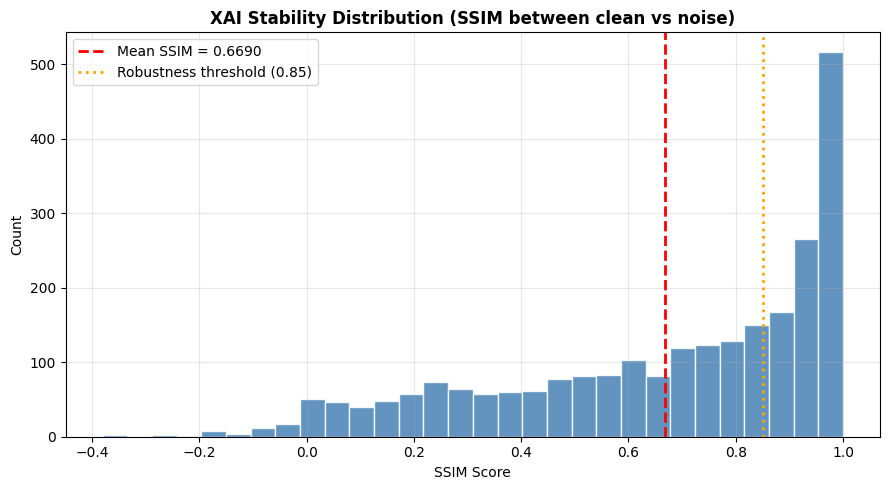

In [12]:
# VALIDATION GATE
if 'metrics_df' not in locals() or metrics_df.empty:
    print("❌ Skipping plot: 'metrics_df' is empty. Ensure Cell 8 ran models successfully.")
elif metrics_df['stability_ssim'].isnull().all():
    print("❌ Skipping plot: 'stability_ssim' contains no valid numerical data.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(metrics_df['stability_ssim'], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
    
    mean_val = metrics_df['stability_ssim'].mean()
    ax.axvline(mean_val, color='red', ls='--', lw=2, label=f"Mean SSIM = {mean_val:.4f}")
    ax.axvline(0.85, color='orange', ls=':', lw=2, label="Robustness threshold (0.85)")
    
    ax.set_title("XAI Stability Distribution (SSIM between clean vs noise)", fontsize=12, fontweight='bold')
    ax.set_xlabel("SSIM Score"); ax.set_ylabel("Count")
    ax.legend(); ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'stability_distribution.png'), dpi=150)
    plt.show()
    plt.close()

In [13]:
print("\nRunning Pointing Game localization check …")

def is_peak_in_center(heatmap: np.ndarray, border_frac: float = 0.15) -> bool:
    H, W = heatmap.shape
    border_h, border_w = int(H * border_frac), int(W * border_frac)
    peak_idx = np.unravel_index(np.argmax(heatmap), heatmap.shape)
    return (border_h <= peak_idx[0] < H - border_h and border_w <= peak_idx[1] < W - border_w)

loc_results = []
for _, row in tqdm(eval_merged.head(N_EVAL).iterrows(), total=N_EVAL, desc="Localization"):
    try:
        hmap_filename = os.path.basename(str(row['ensemble_hmap']))
        hmap_path = None
        for root, dirs, files in os.walk(XAI_DIR):
            if hmap_filename in files:
                hmap_path = os.path.join(root, hmap_filename)
                break
                
        if hmap_path:
            hmap = np.load(hmap_path).astype(np.float32)
            if hmap.ndim > 2: hmap = hmap.squeeze()
            loc_results.append({'image_id': row['image_id'], 'peak_in_center': int(is_peak_in_center(hmap))})
    except:
        pass

# VALIDATION GATE
if loc_results:
    loc_df = pd.DataFrame(loc_results)
    hit_rate = loc_df['peak_in_center'].mean() * 100
    print(f"\n  Localization Hit Rate (peak in central region): {hit_rate:.1f}%")
    loc_df.to_csv(os.path.join(OUTPUT_DIR, 'localization_results.csv'), index=False)

    with open(os.path.join(OUTPUT_DIR, 'xai_eval_summary_all.txt'), 'a') as f:
        f.write(f"\n\n  LOCALIZATION (Pointing Game)\n  Hit rate : {hit_rate:.1f}%\n")
else:
    print("❌ Skipping Localization Check: No heatmaps successfully processed.")
    
print("\n✅ Notebook 2 Binary Section Complete.")


Running Pointing Game localization check …


Localization: 100%|██████████| 500/500 [00:10<00:00, 46.40it/s]


  Localization Hit Rate (peak in central region): 70.4%

✅ Notebook 2 Binary Section Complete.


---
## Part 2 — Multiclass (Severity) Heatmap Evaluation

Evaluates the **ordinal severity heatmaps** generated by notebook1 for the 
CORAL multiclass models. Applies the same SSIM Stability and Faithfulness metrics 
already computed for the binary heatmaps above.

Also includes **Deletion AUC** and **Insertion AUC** as gold-standard perturbation 
tests — these work identically for multiclass: we measure how quickly the 
model's confidence in the predicted severity class drops as we delete the 
most important pixels indicated by the heatmap.


In [14]:
# ── Part 2 Config: Severity Heatmap Paths & Architecture ─────────────────────
import torch, torch.nn.functional as F
import timm

# Severity heatmap directories (produced by notebook1)
MULTI_OUT = '/kaggle/input/datasets/bhavikakadlecha/severity-heatmap-output/xai_outputs/multiclass'
MULTI_OUT_2 = '/kaggle/input/notebooks/bhavikakadlecha/swin-only/xai_outputs/multiclass'
SEV_HMAP_DIRS = {
    'DenseNet'     : os.path.join(MULTI_OUT, 'heatmaps_densenet'),
    'EfficientNet' : os.path.join(MULTI_OUT, 'heatmaps_efficientnet'),
    'Swin'         : os.path.join(MULTI_OUT_2, 'heatmaps_swin'),
}

# Severity model checkpoint paths
SEV_DENSENET_CKPT  = '/kaggle/input/notebooks/nandini143/densenet-121-ordinal-severity/densenet_severity/densenet_severity_best.pth'
SEV_EFFNET_CKPT    = '/kaggle/input/notebooks/nandini143/efficientnetv2-ordinal-severity/effnet_severity_best.pth'
SEV_SWIN_CKPT = '/kaggle/input/notebooks/nandini143/swin-tiny-ordinal-severity/swin_severity/swin_severity_best.pth'
# Severity CSV (for image IDs and metadata)
SEVERITY_CSV    = '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/severity_train_folds.csv'
SEVERITY_IMGDIR = '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/preprocessed_images'
SEVERITY_META_DIM = 9
SEVERITY_NUM_OUTPUTS = 3
STAGE_NAMES = {0: 'AK', 1: 'BCC', 2: 'SCC', 3: 'MEL'}

N_SEV_STABILITY = 100   # images for SSIM stability evaluation
N_SEV_PERTURB   = 50    # images for deletion/insertion AUC

print('Severity eval config ready.')
print(f'  Severity heatmap root: {MULTI_OUT}')


Severity eval config ready.
  Severity heatmap root: /kaggle/input/datasets/bhavikakadlecha/severity-heatmap-output/xai_outputs/multiclass


In [15]:
# ── Severity Architecture (needed for Faithfulness / Deletion metric) ─────────

class TabularMLP_Sev(torch.nn.Module):
    def __init__(self, in_dim, hidden=64, out=32, dropout=0.2, gelu=True):
        super().__init__()
        act = torch.nn.GELU() if gelu else torch.nn.ReLU(inplace=True)
        self.net = torch.nn.Sequential(
            torch.nn.Linear(in_dim, hidden), torch.nn.BatchNorm1d(hidden), act,
            torch.nn.Dropout(dropout), torch.nn.Linear(hidden, out), act)
    def forward(self, x): return self.net(x)

class MetadataSeverityModel_Eval(torch.nn.Module):
    def __init__(self, model_name, num_outputs, meta_dim,
                 drop_rate=0.3, drop_path_rate=0.0, use_gelu=True):
        super().__init__()
        kwargs = dict(pretrained=False, num_classes=0, drop_rate=drop_rate)
        if drop_path_rate > 0: kwargs['drop_path_rate'] = drop_path_rate
        self.backbone  = timm.create_model(model_name, **kwargs)
        feat_dim       = self.backbone.num_features
        self.use_meta  = meta_dim > 0
        if self.use_meta:
            self.meta_mlp = TabularMLP_Sev(meta_dim, 64, 32, 0.2, use_gelu)
            fusion_dim = feat_dim + 32
        else:
            fusion_dim = feat_dim
        norm = (torch.nn.BatchNorm1d(fusion_dim) if 'densenet' in model_name
                else torch.nn.LayerNorm(fusion_dim))
        act  = (torch.nn.ReLU(inplace=True) if 'densenet' in model_name
                else torch.nn.GELU())
        hidden = 512 if 'densenet' in model_name else 256
        self.head = torch.nn.Sequential(norm, torch.nn.Linear(fusion_dim, hidden),
                                        act, torch.nn.Dropout(drop_rate),
                                        torch.nn.Linear(hidden, num_outputs))
    def forward(self, images, meta=None):
        feat = self.backbone(images)
        if self.use_meta and meta is not None:
            feat = torch.cat([feat, self.meta_mlp(meta)], dim=1)
        return self.head(feat)

def load_severity_model_eval(model_name, ckpt_path, meta_dim,
                              drop_rate=0.3, drop_path_rate=0.0, use_gelu=True):
    model = MetadataSeverityModel_Eval(model_name, SEVERITY_NUM_OUTPUTS, meta_dim,
                                       drop_rate, drop_path_rate, use_gelu)
    ckpt  = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    state = ckpt.get('model_state', ckpt.get('model_state_dict', ckpt))
    model.load_state_dict(state, strict=False)
    model.to(DEVICE).eval()
    return model

def coral_to_label(logits):
    return int((torch.sigmoid(logits) > 0.5).sum().item())

print('Severity eval architectures defined.')


Severity eval architectures defined.


Severity SSIM:   0%|          | 0/100 [00:00<?, ?it/s]


Severity Heatmap SSIM Stability (higher = more consistent across models):
                          count   mean    std    min    25%    50%    75%    max
pair                                                                            
DenseNet vs EfficientNet  100.0  0.148  0.092  0.005  0.083  0.132  0.198  0.469


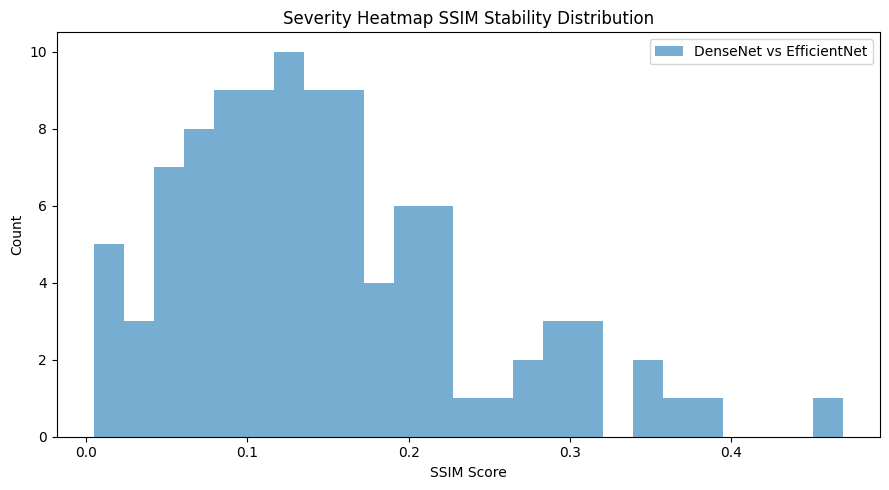

In [16]:
# ── Rec 2: SSIM Stability for Severity Heatmaps ──────────────────────────────
import pandas as pd
import numpy as np
from skimage.metrics import structural_similarity as ssim
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from tqdm.auto import tqdm

sev_df = pd.read_csv(SEVERITY_CSV)
site_cols = [c for c in sev_df.columns if c.startswith('site_')]
actual_meta_dim = 3 + len(site_cols)

sev_transform = A.Compose([
    A.Resize(384, 384),
    A.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    ToTensorV2(),
])

def load_sev_hmap(hmap_dir, image_id, size=224):
    fpath = os.path.join(hmap_dir, f'{image_id}.npy')
    if not os.path.exists(fpath): return None
    h = np.load(fpath).astype(np.float32)
    t = torch.from_numpy(h).unsqueeze(0).unsqueeze(0)
    return F.interpolate(t, (size,size), mode='bilinear', align_corners=False).squeeze().numpy()

# Compute pairwise SSIM between each model's severity heatmaps for same image
sev_ssim_scores = []
sample_ids = sev_df['image'].astype(str).tolist()[:N_SEV_STABILITY]

for img_id in tqdm(sample_ids, desc='Severity SSIM'):
    hmaps = {}
    for name, hdir in SEV_HMAP_DIRS.items():
        h = load_sev_hmap(hdir, img_id)
        if h is not None:
            hmaps[name] = h
    if len(hmaps) >= 2:
        names_list = list(hmaps.keys())
        pairs = [(names_list[i], names_list[j])
                 for i in range(len(names_list))
                 for j in range(i+1, len(names_list))]
        for n1, n2 in pairs:
            score = ssim(hmaps[n1], hmaps[n2], data_range=1.0)
            sev_ssim_scores.append({'image_id': img_id, 'pair': f'{n1} vs {n2}', 'ssim': score})

sev_ssim_df = pd.DataFrame(sev_ssim_scores)
if not sev_ssim_df.empty:
    print('\nSeverity Heatmap SSIM Stability (higher = more consistent across models):')
    print(sev_ssim_df.groupby('pair')['ssim'].describe().round(3).to_string())
    sev_ssim_df.to_csv(os.path.join(OUTPUT_DIR, 'severity_ssim_stability.csv'), index=False)

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9,5))
    for pair, grp in sev_ssim_df.groupby('pair'):
        ax.hist(grp['ssim'], bins=25, alpha=0.6, label=pair)
    ax.set_xlabel('SSIM Score'); ax.set_ylabel('Count')
    ax.set_title('Severity Heatmap SSIM Stability Distribution')
    ax.legend(); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'severity_ssim_distribution.png'), dpi=150)
    plt.show(); plt.close()
else:
    print('No severity SSIM scores computed. Check that severity heatmaps exist in MULTI_OUT.')


In [17]:
# ── Rec 3: Deletion & Insertion AUC — Severity (Multiclass) ──────────────────
#
# Deletion AUC: Progressively mask out the top-K% pixels the heatmap says are
#   most important. If the heatmap is correct, the model's confidence in the
#   predicted severity class should DROP sharply. Lower AUC = better heatmap.
#
# Insertion AUC: Start from a blurred image, progressively REVEAL the top-K%
#   pixels. If the heatmap is correct, confidence should RISE sharply.
#   Higher AUC = better heatmap.

STEPS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
SEV_PERTURB_RESULTS = []

# Load severity DenseNet for perturbation (primary reference model)
print('Loading DenseNet-121 severity model for perturbation testing...')
sev_model_perturb = load_severity_model_eval(
    'densenet121', SEV_DENSENET_CKPT, actual_meta_dim,
    drop_rate=0.3, drop_path_rate=0.0, use_gelu=False)
sev_model_perturb.eval()

sample_ids_perturb = sev_df['image'].astype(str).tolist()[:N_SEV_PERTURB]
dummy_meta = torch.zeros(1, actual_meta_dim, device=DEVICE)

for img_id in tqdm(sample_ids_perturb, desc='Sev Deletion/Insertion'):
    # Load heatmap from DenseNet severity heatmaps
    hmap = load_sev_hmap(SEV_HMAP_DIRS['DenseNet'], img_id, size=384)
    if hmap is None:
        continue
    # Load image
    row = sev_df[sev_df['image'].astype(str) == img_id]
    if len(row) == 0: continue
    img_path = os.path.join(SEVERITY_IMGDIR, f'{img_id}.jpg')
    if not os.path.exists(img_path): continue
    raw = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    aug  = sev_transform(image=raw)['image'].unsqueeze(0).to(DEVICE)

    # True predicted class (from heatmap — we explain the dominant class)
    with torch.no_grad():
        logits = sev_model_perturb(aug, dummy_meta)
        pred_class = coral_to_label(logits[0])
        logit_idx  = max(pred_class - 1, 0)
        base_conf  = torch.sigmoid(logits[0, logit_idx]).item()

    if base_conf < 0.1:
        continue  # model not confident in any class for this image

    # Flat sorted pixel indices by heatmap importance (descending)
    flat_hmap = cv2.resize(hmap, (384, 384)).flatten()
    sorted_idx = np.argsort(flat_hmap)[::-1]   # most important first
    blurred = torch.from_numpy(
        cv2.GaussianBlur(raw, (51, 51), 0).astype(np.float32) / 255.
    ).permute(2, 0, 1).unsqueeze(0)
    blurred_aug = sev_transform(image=cv2.GaussianBlur(raw,(51,51),0))['image'].unsqueeze(0).to(DEVICE)

    del_scores, ins_scores = [], []
    for step in STEPS:
        n_pixels = int(step * 384 * 384)
        mask = torch.ones(1, 1, 384, 384, device=DEVICE)
        if n_pixels > 0:
            rows_m = sorted_idx[:n_pixels] // 384
            cols_m = sorted_idx[:n_pixels] % 384
            mask[0, 0, rows_m, cols_m] = 0.0

        # Deletion: original * mask (blank out important pixels)
        del_img  = aug * mask
        # Insertion: blurred baseline + original where mask=1
        ins_img  = blurred_aug * (1 - mask) + aug * mask

        with torch.no_grad():
            del_conf = torch.sigmoid(sev_model_perturb(del_img, dummy_meta)[0, logit_idx]).item()
            ins_conf = torch.sigmoid(sev_model_perturb(ins_img, dummy_meta)[0, logit_idx]).item()

        del_scores.append(del_conf)
        ins_scores.append(ins_conf)

    # AUC via trapezoidal rule
    del_auc = float(np.trapz(del_scores, STEPS))
    ins_auc = float(np.trapz(ins_scores, STEPS))
    SEV_PERTURB_RESULTS.append({
        'image_id'   : img_id,
        'pred_class' : pred_class,
        'pred_name'  : STAGE_NAMES.get(pred_class, '?'),
        'base_conf'  : base_conf,
        'deletion_auc'  : del_auc,
        'insertion_auc' : ins_auc,
    })

del sev_model_perturb; import gc; gc.collect(); torch.cuda.empty_cache()

sev_perturb_df = pd.DataFrame(SEV_PERTURB_RESULTS)
if not sev_perturb_df.empty:
    sev_perturb_df.to_csv(os.path.join(OUTPUT_DIR, 'severity_perturbation_auc.csv'), index=False)
    print('\nSeverity Deletion / Insertion AUC (per class):')
    print(sev_perturb_df.groupby('pred_name')[['deletion_auc','insertion_auc']].mean().round(4).to_string())
    print(f'\nOverall  Deletion AUC : {sev_perturb_df["deletion_auc"].mean():.4f}  (lower = better heatmap)')
    print(f'Overall  Insertion AUC: {sev_perturb_df["insertion_auc"].mean():.4f}  (higher = better heatmap)')
else:
    print('No perturbation results. Check severity model checkpoint paths.')


Loading DenseNet-121 severity model for perturbation testing...


RuntimeError: Error(s) in loading state_dict for MetadataSeverityModel_Eval:
	size mismatch for head.4.weight: copying a param with shape torch.Size([256, 512]) from checkpoint, the shape in current model is torch.Size([3, 512]).
	size mismatch for head.4.bias: copying a param with shape torch.Size([256]) from checkpoint, the shape in current model is torch.Size([3]).

In [ ]:
# ── Deletion / Insertion AUC Curve Plot ───────────────────────────────────────

# --- CUSTOM PATHS ---
# Enter the directory where your files are saved, and the specific CSV filename.
# You can change PLOT_OUTPUT_DIR to a string like 'D:/NEWSTART/XAI/'
PLOT_OUTPUT_DIR = OUTPUT_DIR  
BINARY_CSV_FILENAME = '/kaggle/input/datasets/bhavikakadlecha/quantitative-xai-evaluation/xai_eval' 
if 'sev_perturb_df' in locals() and not sev_perturb_df.empty:
    # Also reload binary perturbation results if available using your custom paths
    bin_perturb_path = os.path.join(PLOT_OUTPUT_DIR, BINARY_CSV_FILENAME)
    has_binary = os.path.exists(bin_perturb_path)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    for ax, metric, label, color in [
        (axes[0], 'deletion_auc',  'Deletion AUC (lower = better)',  '#e74c3c'),
        (axes[1], 'insertion_auc', 'Insertion AUC (higher = better)', '#2ecc71'),
    ]:
        ax.set_facecolor('#0d0d0d')
        # Plot per-class box
        classes = sev_perturb_df['pred_name'].unique()
        vals = [sev_perturb_df[sev_perturb_df['pred_name']==c][metric].values for c in classes]
        bp = ax.boxplot(vals, labels=classes, patch_artist=True,
                        medianprops=dict(color='white', lw=2))
        palette = ['#3498db','#9b59b6','#f39c12','#e74c3c']
        for patch, col in zip(bp['boxes'], palette):
            patch.set_facecolor(col); patch.set_alpha(0.7)
        ax.set_title(label, color='white', fontweight='bold')
        ax.set_ylabel('AUC', color='white')
        ax.tick_params(colors='white')
        for spine in ax.spines.values(): spine.set_edgecolor('#444')
        ax.set_facecolor('#111')

    fig.patch.set_facecolor('#1a1a2e')
    plt.suptitle('Severity Heatmap Perturbation AUC by Class', color='white',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    # Save using the custom directory
    plt.savefig(os.path.join(PLOT_OUTPUT_DIR, 'severity_perturbation_auc_plot.png'),
                dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show(); plt.close()

   